## 1. Load libraries

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
from scipy.stats import zscore

## 2. Load CSV, JSON and converted SQL data

In [13]:
riders = pd.read_csv("riders - riders.csv (1).csv")
trips = pd.read_json("trips.json")


### Riders: first rows, info, missing, duplicates

In [14]:
display(riders.head())
riders.info()
print("Missing:\n", riders.isnull().sum())
print("Duplicates:", riders.duplicated().sum())

,rider_id,name,age,gender,city,signup_date,total_rides,cancelled_rides,avg_rating
0,R0001,Aarav Das,23,Male,Pune,2020-06-29,56,0,3.76
1,R0002,Ishaan Nair,39,Female,Mumbai,2019-11-23,70,5,4.12
2,R0003,Kavya Reddy,34,Male,Pune,2023-05-04,45,9,3.76
3,R0004,Aarav Nair,19,Other,Kolkata,2019-07-28,464,5,3.19
4,R0005,Diya Reddy,27,Male,Ahmedabad,2021-05-31,294,30,3.53


<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rider_id         300 non-null    str    
 1   name             300 non-null    str    
 2   age              300 non-null    int64  
 3   gender           300 non-null    str    
 4   city             300 non-null    str    
 5   signup_date      300 non-null    str    
 6   total_rides      300 non-null    int64  
 7   cancelled_rides  300 non-null    int64  
 8   avg_rating       300 non-null    float64
dtypes: float64(1), int64(3), str(5)
memory usage: 21.2 KB
Missing:
 rider_id           0
name               0
age                0
gender             0
city               0
signup_date        0
total_rides        0
cancelled_rides    0
avg_rating         0
dtype: int64
Duplicates: 0


### Trips: first rows, info, missing, duplicates

In [15]:
display(trips.head())
trips.info()
print("Missing:\n", trips.isnull().sum())
print("Duplicates:", trips.duplicated().sum())

,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,payment_mode,ride_date,surge_flag
0,T00001,R0037,Zone_10,11.83,74.59,104.88,Cash,2023-11-13,0
1,T00002,R0104,Zone_9,3.86,35.59,40.48,Cash,2023-07-28,1
2,T00003,R0045,Zone_8,4.70,31.03,46.39,Cash,2024-01-14,1
3,T00004,R0089,Zone_2,11.06,59.48,257.64,Cash,2023-12-13,0
4,T00005,R0003,Zone_5,7.28,67.59,72.74,UPI,2023-03-15,1


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   trip_id       2000 non-null   str    
 1   rider_id      2000 non-null   str    
 2   zone          2000 non-null   str    
 3   distance_km   2000 non-null   float64
 4   duration_min  2000 non-null   float64
 5   fare_amount   2000 non-null   float64
 6   payment_mode  2000 non-null   str    
 7   ride_date     2000 non-null   str    
 8   surge_flag    2000 non-null   int64  
dtypes: float64(3), int64(1), str(5)
memory usage: 140.8 KB
Missing:
 trip_id         0
rider_id        0
zone            0
distance_km     0
duration_min    0
fare_amount     0
payment_mode    0
ride_date       0
surge_flag      0
dtype: int64
Duplicates: 0


## 3. Save before-cleaning measurements

In [16]:
rows_before = len(trips)
missing_before = riders.isna().sum().sum() + trips.isna().sum().sum() 
print("Invalid age:", (riders["age"] < 10).sum())
print("Negative distance:", (trips["distance_km"] < 0).sum())
print("Negative fare:", (trips["fare_amount"] < 0).sum())

Invalid age: 0
Negative distance: 0
Negative fare: 0


## 4. Remove duplicate records

In [17]:
riders = riders.drop_duplicates().copy()
trips = trips.drop_duplicates().copy()


## 5. Invalid values: remove unrealistic records

In [18]:
riders.loc[riders["age"] < 10, "age"] = np.nan
trips = trips[(trips["distance_km"].isna()) | (trips["distance_km"] >= 0)].copy()
trips = trips[(trips["fare_amount"].isna()) | (trips["fare_amount"] >= 0)].copy()
trips = trips[~((trips["distance_km"] == 0) & (trips["fare_amount"] > 0))].copy()

## 6. Mean imputation for rider numeric columns

In [19]:
mean_cols = ["age", "avg_rating"]
mean_imp = SimpleImputer(strategy="mean")
riders[mean_cols] = mean_imp.fit_transform(riders[mean_cols])

## 7. Most-frequent imputation for categorical values

In [20]:
cat_imp = SimpleImputer(strategy="most_frequent")
for frame, cols in [(riders,["gender","city"]),(trips,["payment_mode"])]:
    frame[cols] = cat_imp.fit_transform(frame[cols])

## 8. KNN imputation: distance, duration, fare

In [21]:
knn_cols = ["distance_km", "duration_min", "fare_amount"]
knn = KNNImputer(n_neighbors=5)
trips[knn_cols] = knn.fit_transform(trips[knn_cols])

## 9. Convert dates

In [22]:
riders["signup_date"] = pd.to_datetime(riders["signup_date"], errors="coerce", format="mixed")
trips["ride_date"] = pd.to_datetime(trips["ride_date"], errors="coerce", format="mixed")
print(trips["ride_date"].head())

0   2023-11-13
1   2023-07-28
2   2024-01-14
3   2023-12-13
4   2023-03-15
Name: ride_date, dtype: datetime64[us]


## 10. Z-score outlier detection (fare, distance)

In [23]:
fare_z = np.abs(zscore(trips["fare_amount"], nan_policy="omit"))
distance_z = np.abs(zscore(trips["distance_km"], nan_policy="omit"))
print("Fare outliers before:", (fare_z > 3).sum())
print("Distance outliers before:", (distance_z > 3).sum())

Fare outliers before: 16
Distance outliers before: 3


## 11. IQR outlier detection for duration

In [24]:
q1 = trips["duration_min"].quantile(.25)
q3 = trips["duration_min"].quantile(.75)
iqr = q3 - q1
duration_before = ((trips["duration_min"] < q1-1.5*iqr) | (trips["duration_min"] > q3+1.5*iqr)).sum()
print("Duration outliers before:", duration_before)

Duration outliers before: 18


## 12. Winsorization: cap extreme fare and distance at 1st/99th percentiles

In [25]:
before_stats = trips[["fare_amount","distance_km","duration_min"]].describe().loc[["mean","std","min","max"]]
for col in ["fare_amount","distance_km"]:
    trips[col] = trips[col].clip(trips[col].quantile(.01), trips[col].quantile(.99))
print("Before:")
display(before_stats)
print("After:")
display(trips[["fare_amount","distance_km","duration_min"]].describe().loc[["mean","std","min","max"]])

Before:


,fare_amount,distance_km,duration_min
mean,134.600375,8.247420,61.883410
std,85.521989,4.450904,35.980603
min,0.250000,0.020000,0.190000
max,472.290000,25.860000,201.070000


After:


,fare_amount,distance_km,duration_min
mean,134.225530,8.232736,61.883410
std,84.222681,4.405750,35.980603
min,3.267400,0.229700,0.190000
max,379.682600,18.590400,201.070000


## 13. Cap duration using IQR bounds

In [26]:
trips["duration_min"] = trips["duration_min"].clip(lower=max(0,q1-1.5*iqr), upper=q3+1.5*iqr)

## 14. Outlier comparison

In [27]:
fare_after = (np.abs(zscore(trips["fare_amount"])) > 3).sum()
distance_after = (np.abs(zscore(trips["distance_km"])) > 3).sum()
q1a,q3a = trips["duration_min"].quantile([.25,.75])
duration_after = ((trips["duration_min"] < q1a-1.5*(q3a-q1a)) | (trips["duration_min"] > q3a+1.5*(q3a-q1a))).sum()
outlier_summary = pd.DataFrame({"Before": [(fare_z>3).sum(),(distance_z>3).sum(),duration_before], "After":[fare_after,distance_after,duration_after]},index=["Fare Z-score","Distance Z-score","Duration IQR"])
display(outlier_summary)

,Before,After
Fare Z-score,16,0
Distance Z-score,3,0
Duration IQR,18,0


## 15. Datetime features (hour unavailable in source)

In [28]:
trips["day_of_week"] = trips["ride_date"].dt.dayofweek
trips["month"] = trips["ride_date"].dt.month
trips["hour"] = np.nan  # Only date is recorded; cannot infer hour
print(trips[["ride_date","hour","day_of_week","month"]].head())

   ride_date  hour  day_of_week  month
0 2023-11-13   NaN            0     11
1 2023-07-28   NaN            4      7
2 2024-01-14   NaN            6      1
3 2023-12-13   NaN            2     12
4 2023-03-15   NaN            2      3


## 16. Label encode gender

In [29]:
le = LabelEncoder()
riders["gender_encoded"] = le.fit_transform(riders["gender"])
display(riders[["gender","gender_encoded"]].head())

,gender,gender_encoded
0,Male,1
1,Female,0
2,Male,1
3,Other,2
4,Male,1


## 18. Merge all three datasets

In [30]:
df = trips.merge(riders,on="rider_id",how="left",validate="many_to_one")


## 19. One-hot encode payment mode and zone name

In [31]:
df = pd.get_dummies(df,columns=["payment_mode"],dtype=int)

## 20. Ride frequency binning (based on observed trip logs)

In [32]:
df["ride_count"] = df.groupby("rider_id")["trip_id"].transform("count")
df["ride_frequency"] = pd.cut(df["ride_count"],bins=[0,5,15,np.inf],labels=["Low","Medium","High"])
display(df[["rider_id","ride_count","ride_frequency"]].head())

,rider_id,ride_count,ride_frequency
0,R0037,8,Medium
1,R0104,9,Medium
2,R0045,9,Medium
3,R0089,9,Medium
4,R0003,10,Medium


## 21. Log and square-root transformations

In [33]:
df["fare_log"] = np.log1p(df["fare_amount"])
df["distance_log"] = np.log1p(df["distance_km"])
df["duration_sqrt"] = np.sqrt(df["duration_min"].clip(lower=0))

## 22. Scaling: before statistics

In [34]:
scale_cols = ["fare_amount","distance_km","duration_min"]
display(df[scale_cols].agg(["mean","std","min","max"]))

,fare_amount,distance_km,duration_min
mean,134.225530,8.232736,61.770420
std,84.222681,4.405750,35.634621
min,3.267400,0.229700,0.190000
max,379.682600,18.590400,160.315000


## 23. StandardScaler

In [35]:
standard = StandardScaler()
standard_values = standard.fit_transform(df[scale_cols])
for i,col in enumerate(scale_cols):
    df[col+"_standard"] = standard_values[:,i]
display(df[[c+"_standard" for c in scale_cols]].agg(["mean","std","min","max"]))

,fare_amount_standard,distance_km_standard,duration_min_standard
mean,8.881784e-17,-2.131628e-16,-3.019807e-17
std,1.000250e+00,1.000250e+00,1.000250e+00
min,-1.555292e+00,-1.816952e+00,-1.728539e+00
max,2.915111e+00,2.351531e+00,2.766108e+00


## 24. MinMaxScaler

In [36]:
minmax = MinMaxScaler()
minmax_values = minmax.fit_transform(df[scale_cols])
for i,col in enumerate(scale_cols):
    df[col+"_minmax"] = minmax_values[:,i]
display(df[[c+"_minmax" for c in scale_cols]].agg(["mean","std","min","max"]))

,fare_amount_minmax,distance_km_minmax,duration_min_minmax
mean,0.347909,0.435879,0.384577
std,0.223749,0.239955,0.222543
min,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000


## 25. Feature: average ride distance per rider

In [37]:
df["avg_ride_distance"] = df.groupby("rider_id")["distance_km"].transform("mean")

## 26. Feature: average ride fare per rider

In [38]:
df["avg_ride_fare"] = df.groupby("rider_id")["fare_amount"].transform("mean")

## 27. Feature: peak hour (unknown, do not invent time)

In [39]:
df["is_peak_hour"] = pd.Series(pd.NA,index=df.index,dtype="Int64")
print("Peak-hour data unavailable: ride_date has no time component")

Peak-hour data unavailable: ride_date has no time component


## 28. Feature: days since signup

In [40]:
today = pd.Timestamp.today().normalize()
df["days_since_signup"] = (today - df["signup_date"]).dt.days

## 29. Feature: cancellation rate from rider account totals

In [41]:
df["ride_cancellation_rate"] = df["cancelled_rides"] / df["total_rides"].replace(0,np.nan)
df["ride_cancellation_rate"] = df["ride_cancellation_rate"].fillna(0)

## 30. Feature: fare-per-km threshold and existing surge flag

In [42]:
df["fare_per_km"] = df["fare_amount"] / df["distance_km"].replace(0,np.nan)
threshold = df["fare_per_km"].median() * 1.5
df["surge_by_threshold"] = (df["fare_per_km"] > threshold).astype(int)
# Existing surge_flag is retained as the recorded flag; derived rule is a separate column.
display(df[["surge_flag","surge_by_threshold","fare_per_km"]].head())

,surge_flag,surge_by_threshold,fare_per_km
0,0,0,8.865596
1,1,0,10.487047
2,1,0,9.870213
3,0,0,23.294756
4,1,0,9.991758


## 31. Final quality checks and summary

In [43]:
rows_after = len(df)
missing_after = df.drop(columns=["hour","is_peak_hour"]).isna().sum().sum()
summary = pd.DataFrame({"Metric":["Trip rows","Missing values (excluding unavailable hour fields)","Fare outliers (Z)","Distance outliers (Z)","Duration outliers (IQR)","New engineered features"],"Before":[rows_before,missing_before,(fare_z>3).sum(),(distance_z>3).sum(),duration_before,0],"After":[rows_after,missing_after,fare_after,distance_after,duration_after,7]})
display(summary)
print("Missing by column:")
print(df.isna().sum()[df.isna().sum()>0])

,Metric,Before,After
0,Trip rows,2000,2000
1,Missing values (excluding unavailable hour fie...,0,0
2,Fare outliers (Z),16,0
3,Distance outliers (Z),3,0
4,Duration outliers (IQR),18,0
5,New engineered features,0,7


Missing by column:
hour            2000
is_peak_hour    2000
dtype: int64


## 32. Export final CSV

In [44]:
df.to_csv("final_prepared_rides_dataset.csv",index=False)
print("Saved final_prepared_rides_dataset.csv")

Saved final_prepared_rides_dataset.csv


## 33. Bonus: ride demand by day of week (hourly data not available)

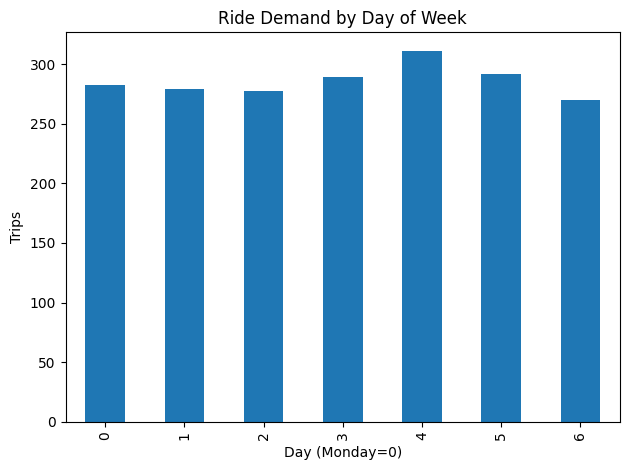

In [45]:
df["day_of_week"].value_counts().sort_index().plot(kind="bar",title="Ride Demand by Day of Week")
plt.xlabel("Day (Monday=0)")
plt.ylabel("Trips")
plt.tight_layout()
plt.savefig("ride_demand_by_weekday.png")
plt.show()

## 34. Bonus: surge vs no surge

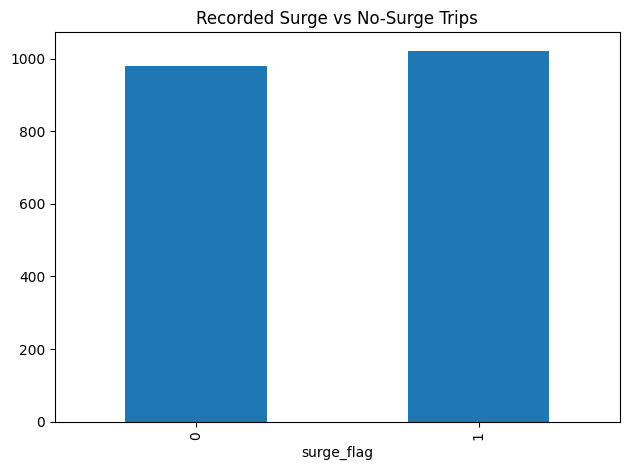

In [46]:
df["surge_flag"].value_counts().sort_index().plot(kind="bar")
plt.title("Recorded Surge vs No-Surge Trips")
plt.tight_layout()
plt.savefig("surge_patterns.png")
plt.show()